<a href="https://colab.research.google.com/github/sanithi20250795-iit/telco-churn-cw/blob/main/churn_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Telco Customer Churn Prediction

1.Load the data

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
uploaded = files.upload()   # choose the CSV when the button appears

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


2. Exploratory Data Analysis (Task 1 )

The dataset has 7,043 customers and 21 columns: demographics (gender, SeniorCitizen, Partner, Dependents), services (phone, internet, security, streaming...), account information (tenure, Contract, PaymentMethod, MonthlyCharges, TotalCharges) and the target Churn.

In [2]:
df.info()          # column types and non-null counts
df.describe()      # statistics for numeric columns
df.shape
df.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


np.int64(0)

Data quality note: TotalCharges is stored as text (object) even though it is a number. This happens because 11 rows contain a blank space instead of a value. We convert it to numeric below; the blanks become NaN.

In [4]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(df.isnull().sum()[df.isnull().sum() > 0])
print('\nRows with missing TotalCharges all have tenure =', df[df['TotalCharges'].isnull()]['tenure'].unique())

TotalCharges    11
dtype: int64

Rows with missing TotalCharges all have tenure = [0]


Insight: the 11 missing TotalCharges rows all have tenure 0, meaning they are brand-new customers who have not been billed yet. Setting them to 0 is therefore logical, and better than dropping rows or imputing a mean

2.1 Target distribution

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


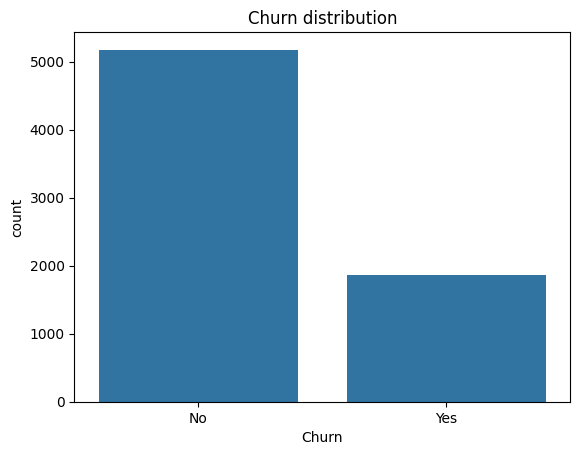

In [5]:
print(df['Churn'].value_counts(normalize=True))
sns.countplot(x='Churn', data=df)
plt.title('Churn distribution')
plt.show()

Insight: about 73.5% of customers stayed and 26.5% churned. The classes are imbalanced, so accuracy is misleading (a model that always predicts "No churn" would already score about 73%). We therefore use stratified splitting, class weights, and F1, recall and ROC-AUC as the main metrics.

2.2 Contract type , tenure and monthly charges  

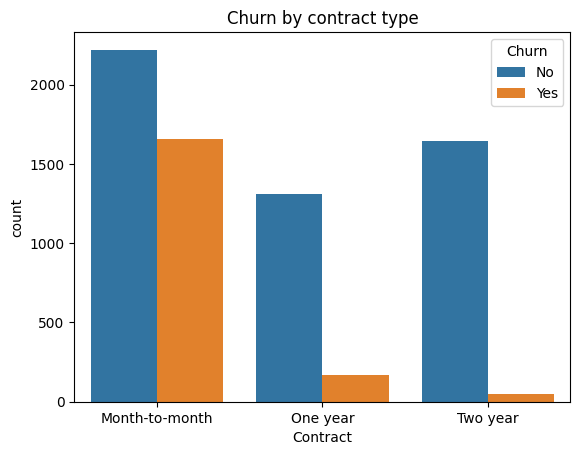

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: Churn, dtype: float64


In [7]:
sns.countplot(x='Contract', hue='Churn', data=df)
plt.title('Churn by contract type');
plt.show()
print(df.groupby('Contract')['Churn'].apply(lambda s: (s == 'Yes').mean()).round(3))

Insight: month-to-month customers churn at about 42.7%, one-year at 11.3% and two-year at only 2.8%. Contract length is likely one of the strongest predictors: customers without a commitment can leave at any time.

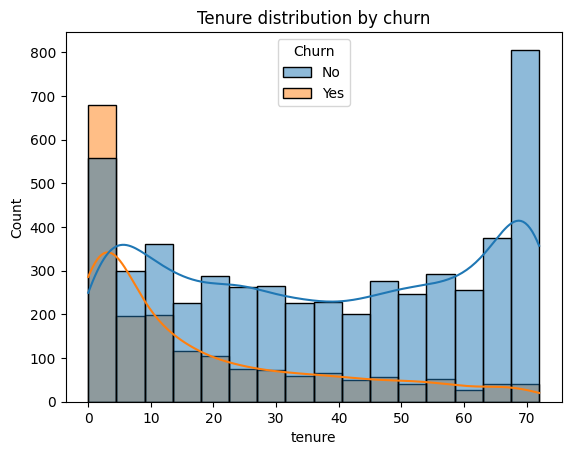

Churn
No     38.0
Yes    10.0
Name: tenure, dtype: float64


In [8]:
sns.histplot(data=df, x='tenure', hue='Churn', kde=True)
plt.title('Tenure distribution by churn');
plt.show()
print(df.groupby('Churn')['tenure'].median())

Insight: churners leave early. The median tenure of churners is about 10 months versus 38 months for loyal customers, so the first year is the highest-risk period and a good target for retention campaigns.

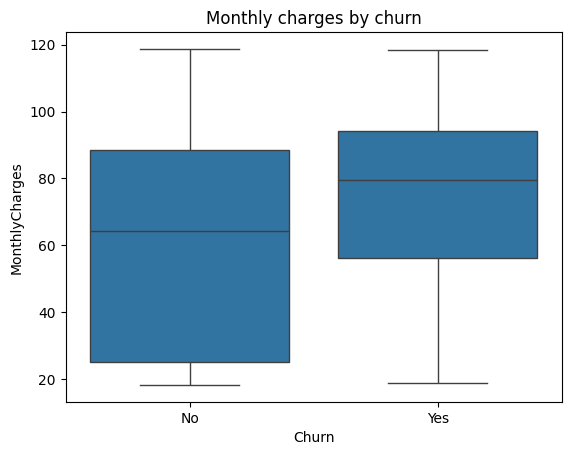

Churn
No     64.425
Yes    79.650
Name: MonthlyCharges, dtype: float64


In [9]:
sns.boxplot(x='Churn', y='MonthlyCharges', data=df)
plt.title('Monthly charges by churn');
plt.show()
print(df.groupby('Churn')['MonthlyCharges'].median())

Insight: churners pay more per month (median about 79.65 versus 64.43). Higher bills, probably fiber and add-on services, are associated with higher churn.

2.3 Services and payment

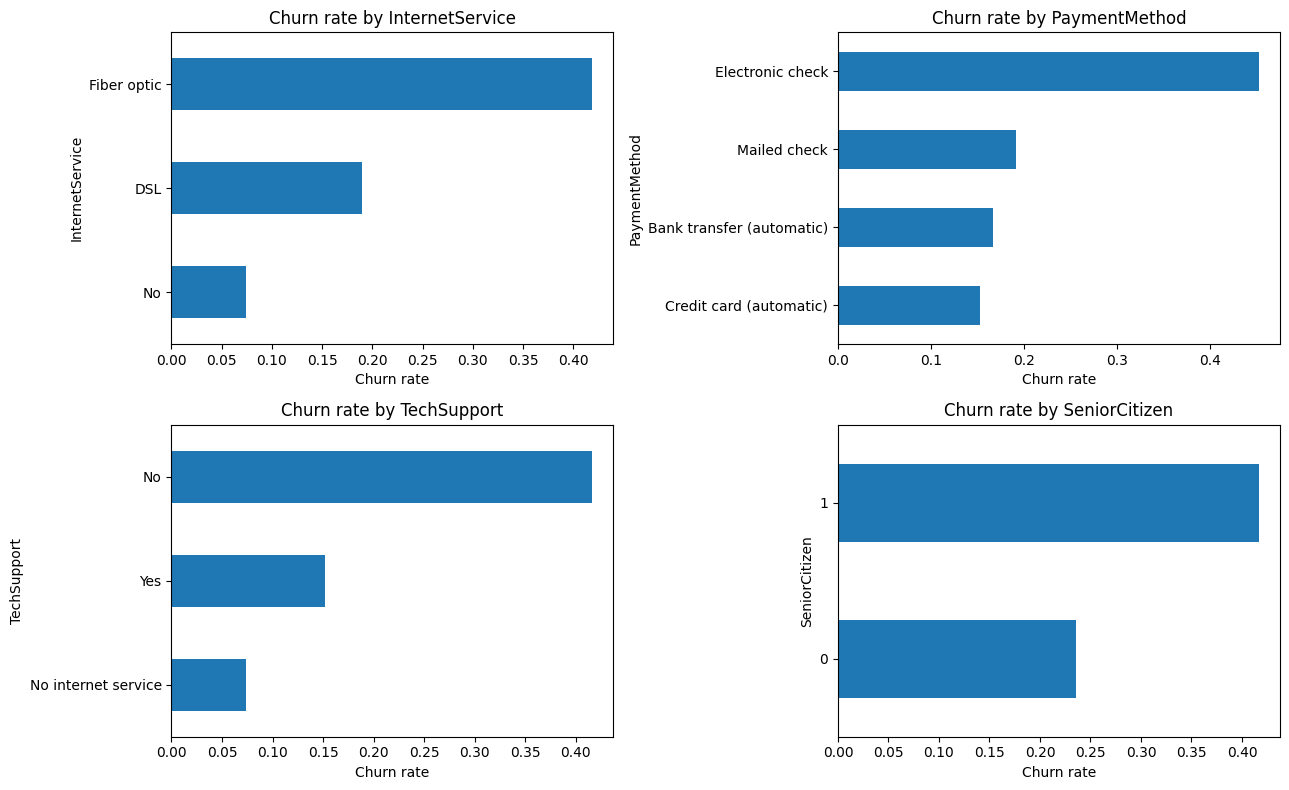

In [10]:
cols = ['InternetService', 'PaymentMethod', 'TechSupport', 'SeniorCitizen']
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, c in zip(axes.ravel(), cols):
    rate = df.assign(c=(df['Churn'] == 'Yes')).groupby(c)['c'].mean().sort_values()
    rate.plot(kind='barh', ax=ax); ax.set_title('Churn rate by ' + c); ax.set_xlabel('Churn rate')
plt.tight_layout(); plt.show()

Insights:

Fiber optic customers churn at about 41.9%, versus 19.0% for DSL and 7.4% for customers without internet. Possible reasons (price, reliability, competition) are hypotheses that the data cannot prove.
Electronic check users churn at about 45.3%, versus roughly 15-19% for the other payment methods. Automatic payment may reflect stronger commitment.
Customers without tech support churn at about 41.6%, versus 15.2% with it.
Senior citizens churn at about 41.7% versus 23.6% for others. Gender has almost no effect (about 26.9% vs 26.2%).

2.4 Correlation of numeric features

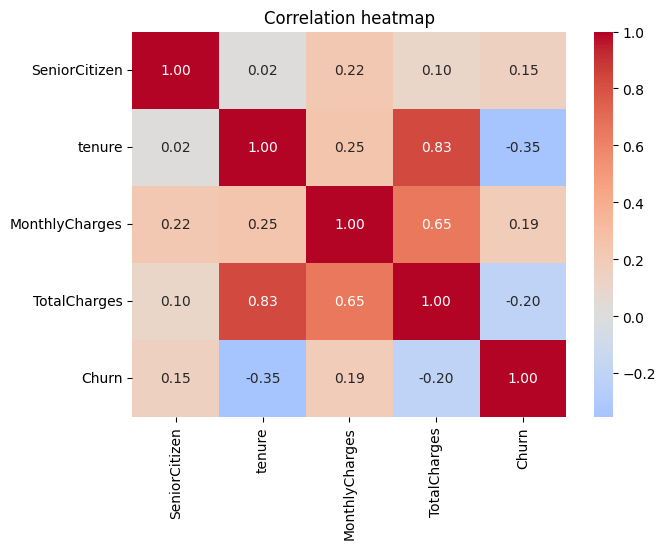

In [11]:
num_df = df[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']].copy()
num_df['Churn'] = (df['Churn'] == 'Yes').astype(int)
plt.figure(figsize=(7, 5))
sns.heatmap(num_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation heatmap'); plt.show()

Insight: tenure and TotalCharges are strongly correlated (about 0.83) because total charges accumulate over time. This multicollinearity can make Logistic Regression coefficients less stable. tenure has the strongest negative correlation with churn (about -0.35).

# 3. Cleaning and preprocessing (Task 2)

In [13]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
                             classification_report)



In [14]:
data = df.copy()
data = data.drop(columns='customerID')
data['TotalCharges'] = data['TotalCharges'].fillna(0)
data['Churn'] = data['Churn'].map({'No': 0, 'Yes': 1})
print('Missing values left:', data.isnull().sum().sum())



Missing values left: 0


In [17]:
X = data.drop(columns='Churn')
y = data['Churn']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Churn rate train/test:', round(y_train.mean(), 3), round(y_test.mean(), 3))

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [c for c in X.columns if c not in num_cols]
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Train: (5634, 19)  Test: (1409, 19)
Churn rate train/test: 0.265 0.265


# 4. Models and hyperparameter tuning (Task 2)

In [18]:
models = {
    'KNN': (KNeighborsClassifier(),
            {'clf__n_neighbors': [5, 11, 21, 31], 'clf__weights': ['uniform', 'distance'],
             'clf__metric': ['euclidean', 'manhattan']}),
    'Logistic Regression': (LogisticRegression(max_iter=2000, class_weight='balanced'),
            {'clf__C': [0.01, 0.1, 1, 10], 'clf__penalty': ['l1', 'l2'], 'clf__solver': ['liblinear']}),
    'Random Forest': (RandomForestClassifier(random_state=42, class_weight='balanced'),
            {'clf__n_estimators': [200, 400], 'clf__max_depth': [5, 10, None],
             'clf__min_samples_split': [2, 10], 'clf__min_samples_leaf': [1, 4]}),
}


In [19]:

def evaluate(model):
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    return dict(Accuracy=accuracy_score(y_test, pred), Precision=precision_score(y_test, pred),
                Recall=recall_score(y_test, pred), F1=f1_score(y_test, pred),
                ROC_AUC=roc_auc_score(y_test, prob))



In [20]:
results, tuned_models = [], {}
for name, (est, grid) in models.items():
    base = Pipeline([('pre', preprocessor), ('clf', est)]).fit(X_train, y_train)
    results.append({'Model': name, 'Setting': 'Baseline', **evaluate(base)})
    gs = GridSearchCV(Pipeline([('pre', preprocessor), ('clf', est)]), grid,
                      cv=cv, scoring='roc_auc', n_jobs=-1).fit(X_train, y_train)
    tuned_models[name] = gs.best_estimator_
    print(name, '| best params:', gs.best_params_, '| CV ROC-AUC:', round(gs.best_score_, 4))
    results.append({'Model': name, 'Setting': 'Tuned', **evaluate(gs.best_estimator_)})

results_df = pd.DataFrame(results).round(3)
results_df

KNN | best params: {'clf__metric': 'euclidean', 'clf__n_neighbors': 31, 'clf__weights': 'uniform'} | CV ROC-AUC: 0.8356
Logistic Regression | best params: {'clf__C': 10, 'clf__penalty': 'l1', 'clf__solver': 'liblinear'} | CV ROC-AUC: 0.8462
Random Forest | best params: {'clf__max_depth': 10, 'clf__min_samples_leaf': 4, 'clf__min_samples_split': 10, 'clf__n_estimators': 400} | CV ROC-AUC: 0.8463


,Model,Setting,Accuracy,Precision,Recall,F1,ROC_AUC
0,KNN,Baseline,0.763,0.554,0.551,0.552,0.793
1,KNN,Tuned,0.795,0.620,0.586,0.602,0.833
2,Logistic Regression,Baseline,0.738,0.504,0.783,0.614,0.842
3,Logistic Regression,Tuned,0.737,0.503,0.783,0.613,0.841
4,Random Forest,Baseline,0.791,0.639,0.492,0.556,0.824
5,Random Forest,Tuned,0.766,0.541,0.770,0.636,0.844


# 5. Evaluation (Task 2)

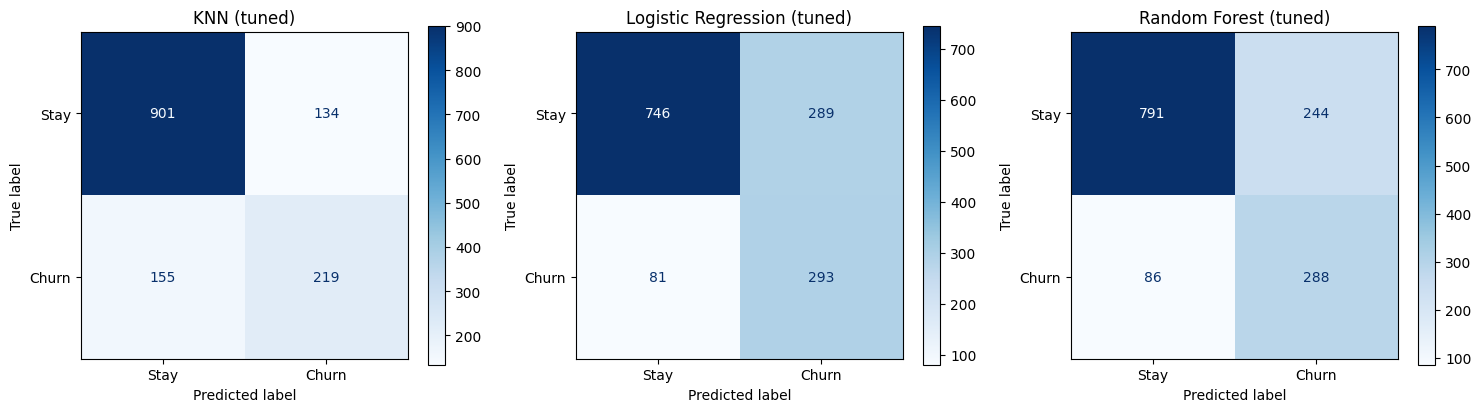

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, m) in zip(axes, tuned_models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, display_labels=['Stay', 'Churn'], cmap='Blues', ax=ax)
    ax.set_title(name + ' (tuned)')
plt.tight_layout(); plt.show()

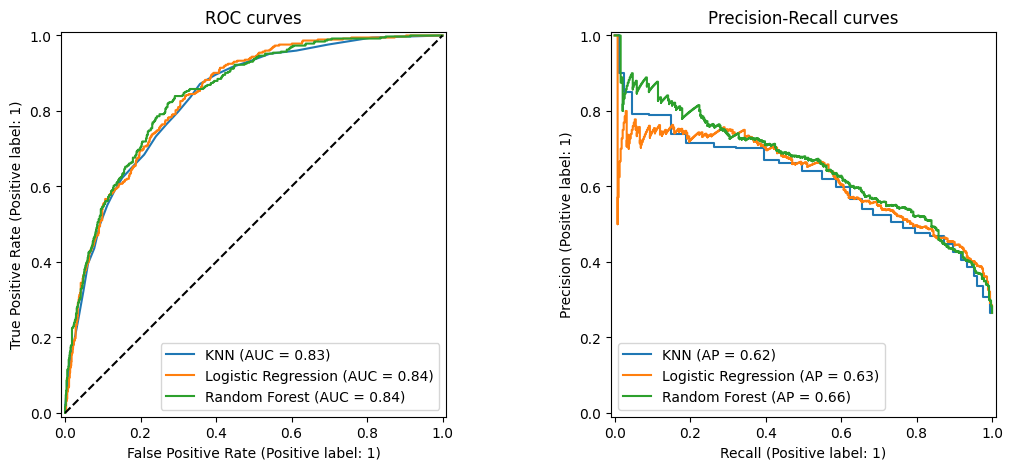

KNN
              precision    recall  f1-score   support

        Stay       0.85      0.87      0.86      1035
       Churn       0.62      0.59      0.60       374

    accuracy                           0.79      1409
   macro avg       0.74      0.73      0.73      1409
weighted avg       0.79      0.79      0.79      1409

Logistic Regression
              precision    recall  f1-score   support

        Stay       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

Random Forest
              precision    recall  f1-score   support

        Stay       0.90      0.76      0.83      1035
       Churn       0.54      0.77      0.64       374

    accuracy                           0.77      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.77   

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, m in tuned_models.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_estimator(m, X_test, y_test, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], 'k--'); axes[0].set_title('ROC curves'); axes[1].set_title('Precision-Recall curves')
plt.show()
for name, m in tuned_models.items():
    print(name)
    print(classification_report(y_test, m.predict(X_test), target_names=['Stay', 'Churn']))

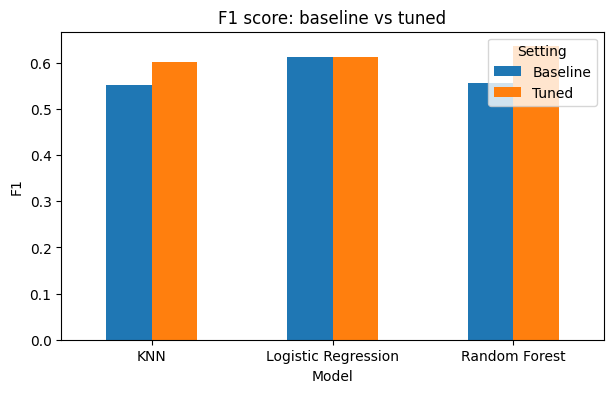

,Model,Setting,Accuracy,Precision,Recall,F1,ROC_AUC
5,Random Forest,Tuned,0.766,0.541,0.770,0.636,0.844
2,Logistic Regression,Baseline,0.738,0.504,0.783,0.614,0.842
3,Logistic Regression,Tuned,0.737,0.503,0.783,0.613,0.841
1,KNN,Tuned,0.795,0.620,0.586,0.602,0.833
4,Random Forest,Baseline,0.791,0.639,0.492,0.556,0.824
0,KNN,Baseline,0.763,0.554,0.551,0.552,0.793


In [23]:
results_df.pivot(index='Model', columns='Setting', values='F1').plot(kind='bar', figsize=(7, 4))
plt.title('F1 score: baseline vs tuned'); plt.ylabel('F1'); plt.xticks(rotation=0); plt.show()
results_df.sort_values('F1', ascending=False)

# 6. Explainability: what drives churn?

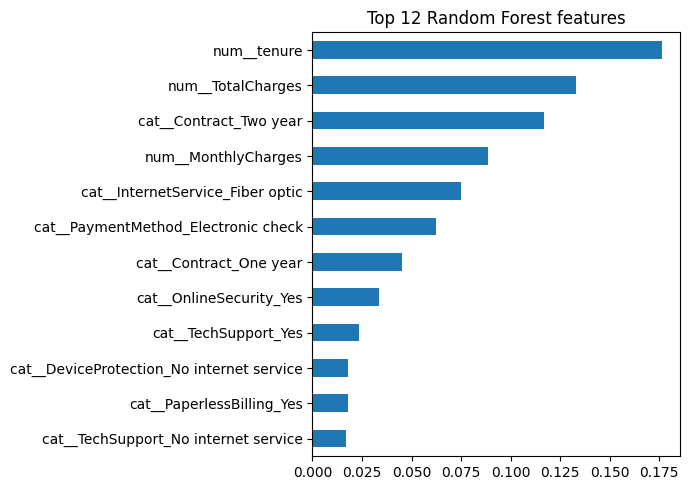

In [24]:
rf = tuned_models['Random Forest']
names = rf.named_steps['pre'].get_feature_names_out()
imp = pd.Series(rf.named_steps['clf'].feature_importances_, index=names).sort_values(ascending=False).head(12)
imp.sort_values().plot(kind='barh', figsize=(7, 5)); plt.title('Top 12 Random Forest features')
plt.tight_layout(); plt.show()



In [25]:
lr = tuned_models['Logistic Regression']
coef = pd.Series(lr.named_steps['clf'].coef_[0], index=lr.named_steps['pre'].get_feature_names_out())
print('Strongest churn drivers (+):'); print(coef.sort_values(ascending=False).head(5).round(2))
print('\nStrongest retention drivers (-):'); print(coef.sort_values().head(5).round(2))

Strongest churn drivers (+):
cat__InternetService_Fiber optic    2.44
cat__StreamingMovies_Yes            0.91
cat__StreamingTV_Yes                0.88
cat__MultipleLines_Yes              0.57
num__TotalCharges                   0.52
dtype: float64

Strongest retention drivers (-):
num__MonthlyCharges                   -2.02
cat__Contract_Two year                -1.45
num__tenure                           -1.19
cat__MultipleLines_No phone service   -1.08
cat__Contract_One year                -0.73
dtype: float64


Interpretation: tenure, contract type, monthly charges and fiber optic internet are the main drivers. Short tenure, month-to-month contracts and fiber service increase churn risk; long tenure and two-year contracts reduce it. Note that coefficients of correlated features (for example tenure and TotalCharges, or the internet add-ons) should be read with caution.

# 7. Fairness audit (supports the AI ethics section)

In [26]:
best = tuned_models['Random Forest']
audit = X_test.copy()
audit['actual'] = y_test.values
audit['pred'] = best.predict(X_test)
rows = []
for col in ['gender', 'SeniorCitizen']:
    for val, d in audit.groupby(col):
        rows.append({'attribute': col, 'group': val, 'n': len(d),
                     'actual_churn_rate': d['actual'].mean(), 'predicted_churn_rate': d['pred'].mean(),
                     'recall': recall_score(d['actual'], d['pred']),
                     'precision': precision_score(d['actual'], d['pred'])})
pd.DataFrame(rows).round(3)

,attribute,group,n,actual_churn_rate,predicted_churn_rate,recall,precision
0,gender,Female,687,0.281,0.380,0.751,0.556
1,gender,Male,722,0.251,0.375,0.790,0.528
2,SeniorCitizen,0,1187,0.233,0.329,0.728,0.515
3,SeniorCitizen,1,222,0.441,0.640,0.888,0.613


Reading the audit: gender groups behave similarly (recall about 0.76 female vs 0.81 male). Senior citizens have a much higher real churn rate (about 44%) and the model catches them more often (recall about 0.89 vs 0.75), and also flags them more. This is not necessarily unfair, but it must be monitored so that seniors are not over-targeted or treated worse

# 8. AI ethics, post-deployment, limitations (Task 3)
Ethics
Fairness and bias: audit performance per group (gender, age/SeniorCitizen); consider removing protected attributes or checking for proxies; make sure retention offers help customers rather than penalise any group.
Privacy and data protection: customer data is personal. Use data minimisation, anonymised identifiers (we dropped customerID), access control, a lawful basis and retention limits (GDPR-style principles).
Transparency and explainability: use feature importance, coefficients and (future work) SHAP so that staff and customers can understand why a customer was flagged.
Harm and accountability: predictions should not be used to worsen service, pricing or access for any customer. Keep a human in the loop and document decisions.
Data limitations: one company, unknown collection method, possible hidden bias.
Post-deployment strategy
Monitor data drift (feature distributions) and concept drift (accuracy, recall, F1 over time).
Retrain on a schedule or when monitoring thresholds are breached; version models and keep a rollback plan.
Track fairness metrics per group continuously.
A/B test retention campaigns to measure the real business effect (and avoid wasting offers).
Feedback loop: feed real churn outcomes back into training data.
Logging and audit trail, plus human review of high-impact decisions.
Limitations
Single static snapshot: no time series or behavioural data (calls, complaints, usage).
Class imbalance and modest test set (1,409 rows), so metrics are noisy.
Limited hyperparameter grids; the default 0.5 threshold is not cost-optimised.
Correlation is not causation; precision is only about 0.5.
Future work
Gradient boosting (XGBoost/LightGBM), SMOTE or cost-sensitive learning, threshold tuning with real retention costs, SHAP explanations, survival analysis / time-based features, nested or repeated cross-validation, probability calibration, per-group fairness constraints.

In [27]:
results_df.to_csv('model_results.csv', index=False)
print('Saved model_results.csv')

Saved model_results.csv
